In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import os.path as osp
import glob
import re
import sys
import json
import yaml
import shutil
import numpy as np
import torch
from socket import gethostname
import warnings
warnings.simplefilter('ignore')

# load packages
import yaml
from munch import Munch
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F

from models import *
from meldataset import build_dataloader
from utils import *
from losses import *
from optimizers import build_optimizer

import pylab as plt

from IPython.display import IFrame

# The flag below controls whether to allow TF32 on matmul.
# torch.backends.cuda.matmul.allow_tf32 = True
# torch.backends.cudnn.allow_tf32 = True
device = "cuda"
# turning the memory timeline into html file
memory_viz_loc = torch.cuda._memory_viz.__file__

In [3]:
config_path = 'Configs/config.yml' #'Models/LibriTTS/config.yml' #'Configs/config_libritts_espeak.yml'

config = yaml.safe_load(open(config_path))
sr = config['preprocess_params'].get('sr', 24000)

log_dir = config['log_dir']

torch.cuda.memory._record_memory_history(max_entries=1000000, stacks='python')
ASR_config = config.get('ASR_config', False)
ASR_path = config.get('ASR_path', False)
text_aligner = load_ASR_models(ASR_path, ASR_config)

# load pretrained F0 model
F0_path = config.get('F0_path', False)
pitch_extractor = load_F0_models(F0_path)

# load BERT model
from Utils.PLBERT.util import load_plbert
BERT_path = config.get('PLBERT_dir', False)
plbert = load_plbert(BERT_path)

In [4]:
config['model_params']['skip_downsamples'] = False
model_params = recursive_munch(config['model_params'])
multispeaker = model_params.multispeaker
model = build_model(model_params, text_aligner, pitch_extractor, plbert)
_ = [model[key].to(device) for key in model]

In [5]:
def load_checkpoint_fixed(model, optimizer, path, load_only_params=True, ignore_modules=[]):
    state = torch.load(path, map_location='cpu')
    params = state['net']
    for key in model:
        if key in params:
            print('%s loaded' % key)
            try:
                model[key].load_state_dict(params[key])
            except:
                from collections import OrderedDict
                state_dict = params[key]
                new_state_dict = OrderedDict()
                for k, v in state_dict.items():
                    name = k[7:] # remove `module.`
                    new_state_dict[name] = v
                # load params
                model[key].load_state_dict(new_state_dict, strict=True)
    #             except:
    #                 _load(params[key], model[key])
  
    _ = [model[key].eval() for key in model]
    
    if not load_only_params:
        epoch = state["epoch"]
        iters = state["iters"]
        optimizer.load_state_dict(state["optimizer"])
    else:
        epoch = 0
        iters = 0
        
    return model, optimizer, epoch, iters



In [6]:
# sr = config['preprocess_params'].get('sr', 24000)
# # wrapped losses for compatibility with mixed precision
# stft_loss = MultiResolutionSTFTLoss().to(device)
# gl = GeneratorLoss(model.mpd, model.msd).to(device)
# dl = DiscriminatorLoss(model.mpd, model.msd).to(device)
# wl = WavLMLoss(model_params.slm.model, 
#                    model.wd, 
#                    sr, 
#                    model_params.slm.sr).to(device)

In [7]:
scheduler_params = {
    "max_lr": float(config['optimizer_params'].get('lr', 1e-4)),
    "pct_start": float(config['optimizer_params'].get('pct_start', 0.0)),
    "epochs": 1, #epochs,
    "steps_per_epoch": 1, # batch_manager.get_step_count(),
}

optimizer = build_optimizer({key: model[key].parameters() for key in model},
                                  scheduler_params_dict= {key: scheduler_params.copy() for key in model},
                               lr=float(config['optimizer_params'].get('lr', 1e-4)))

# pretrained_model = "Models/LJSpeech_original/epoch_2nd_00100.pth" #"Models/LibriTTS/epochs_2nd_00020.pth"
model, optimizer, start_epoch, iters = load_checkpoint_fixed(model,  optimizer, config['pretrained_model'],
                                        load_only_params=config.get('load_only_params', True))
stft_loss = MultiResolutionSTFTLoss().to(device)

gl = GeneratorLoss(model.mpd, model.msd).to(device)

dl = DiscriminatorLoss(model.mpd, model.msd).to(device)

wl = WavLMLoss(model_params.slm.model, 
                model.wd, 
                sr, 
                model_params.slm.sr).to(device)

# _ = [model[key].train() for key in model]

bert loaded
bert_encoder loaded
predictor loaded
decoder loaded
text_encoder loaded
predictor_encoder loaded
style_encoder loaded
diffusion loaded
text_aligner loaded
pitch_extractor loaded
mpd loaded
msd loaded
wd loaded


Some weights of the model checkpoint at microsoft/wavlm-base-plus were not used when initializing WavLMModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing WavLMModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing WavLMModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of WavLMModel were not initialized from the model checkpoint at microsoft/wavlm-base-plus and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for predictio

In [8]:
print(model.decoder.decode[0].conv1.weight[0:10,0,0])
# model.text_encoder.embedding.weight

tensor([ 0.0174, -0.0033, -0.0036, -0.0106,  0.0012,  0.0059,  0.0164,  0.0143,
        -0.0074,  0.0078], grad_fn=<SelectBackward0>)


In [9]:
max_len = 400
split_len = 100
root_path = "../"    
train_list, val_list = get_data_path_list('Data/train_list_LibriTTSR_espeak.txt.verysmall.txt', 'Data/train_list_LibriTTSR_espeak.txt.verysmall.txt')
train_dataloader = build_dataloader(train_list,
                                      root_path,
                                      OOD_data='Data/OOD_texts_LibriTTSR_espeak.txt.verysmall.txt',
                                      # min_length=min_length,
                                      batch_size=4,
                                      validation=True,
                                      num_workers=0,
                                      device=device,
                                      dataset_config={})

batch = next(train_dataloader.__iter__())
waves = batch[0]
batch = [b.to(device) for b in batch[1:]]
texts, input_lengths, _, _, mels, mel_input_length, _ = batch



In [10]:
n_down = model.text_aligner.n_down
mask = (length_to_mask(mel_input_length // (2 ** n_down))).to(device)
text_mask = length_to_mask(input_lengths).to(device)

text_aligner = model.text_aligner.to(device)
ppgs, s2s_pred, s2s_attn = text_aligner(mels, mask, texts)
s2s_attn = s2s_attn.transpose(-1, -2)
s2s_attn = s2s_attn[..., 1:]
s2s_attn = s2s_attn.transpose(-1, -2)
with torch.no_grad():
    attn_mask = (~mask).unsqueeze(-1).expand(mask.shape[0], mask.shape[1], text_mask.shape[-1]).float().transpose(-1, -2)
    attn_mask = attn_mask.float() * (~text_mask).unsqueeze(-1).expand(text_mask.shape[0], text_mask.shape[1], mask.shape[-1]).float()
    attn_mask = (attn_mask < 1)
s2s_attn.masked_fill_(attn_mask, 0.0)

with torch.no_grad():
    mask_ST = mask_from_lens(s2s_attn, input_lengths, mel_input_length // (2 ** n_down))
    s2s_attn_mono = maximum_path(s2s_attn, mask_ST)

text_encoder = model.text_encoder.to(device)
t_en = text_encoder(texts, input_lengths, text_mask)
asr = (t_en @ s2s_attn_mono)

# get clips
# mel_input_length_all = (mel_input_length) # for balanced load
mel_len = int(mel_input_length.min().item() / 2 - 1) #min([int(mel_input_length.min().item() / 2 - 1), max_len // 2])
mel_len_st = int(mel_input_length.min().item() / 2 - 1)

en = []
gt = []
wav = []
st = []



for bib in range(len(mel_input_length)):
    mel_length = int(mel_input_length[bib].item() / 2)

    start = 0 #np.random.randint(0, mel_length - mel_len)
    end = start + mel_len
    en.append(asr[bib, :, start:end])
    gt.append(mels[bib, :, (start * 2):(end * 2)])

    y = waves[bib][(start * 2) * 300:(end * 2) * 300]
    wav.append(torch.from_numpy(y).to(device))
    
    # style reference (better to be different from the GT)
    start_st = np.random.randint(0, mel_length - mel_len_st)
    end_st = start_st + mel_len_st
    st.append(mels[bib, :, (start_st * 2):(end_st * 2)])


en = torch.stack(en)
gt = torch.stack(gt).detach()
st = torch.stack(st).detach()

wav = torch.stack(wav).float().detach()

pitch_extractor = model.pitch_extractor.to(device)
with torch.no_grad():    
    real_norm = log_norm(gt.unsqueeze(1)).squeeze(1).detach()
    F0_real, _, _ = pitch_extractor(gt.unsqueeze(1))

style_encoder = model.style_encoder.to(device)
s = style_encoder(st.unsqueeze(1)) # if multispeaker else gt.unsqueeze(1))


print(list(map(lambda x: x.shape, (en, F0_real, real_norm, s))))
y_rec = model.decoder(en, F0_real, real_norm, s)
print(y_rec.shape)


[torch.Size([4, 512, 123]), torch.Size([4, 246]), torch.Size([4, 246]), torch.Size([4, 128])]
torch.Size([4, 1, 73800])


In [14]:
with torch.no_grad():
    y_rec = model.decoder(en, F0_real, real_norm, s) 
    enpert = en
    enpert[:,:,10] = enpert[:,:,10] + torch.randn_like(enpert[:,:,10]) * 0.1
    y_rec_pert = model.decoder(enpert, F0_real, real_norm, s)

(4, 1, 73800)


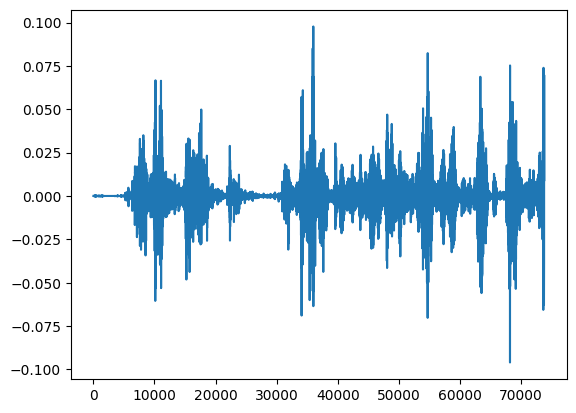

In [19]:
df = (y_rec - y_rec_pert).detach().cpu().numpy()
plt.plot(df[0,0,:])
# plt.plot(y_rec[0,0,:].detach().cpu().numpy())
print(df.shape)

In [10]:
mel_len = mels.shape[-1]
mel_len_min = mel_input_length.min().item()
mel_len_st = mel_len_min // 2

pitch_extractor = model.pitch_extractor.to(device)
style_encoder = model.style_encoder.to(device)

for idx in range(math.floor(mel_len / split_len)):
    start = idx*split_len
    end = min((idx+1)*split_len, mel_len)

    en = asr[:, :, (start//2):(end//2)]
    gt = mels[:, :, start:end].detach()

    wav=[]
    wavidx = slice(start * 300, end * 300)
    full_len = wavidx.stop-wavidx.start
    for bib in range(len(mel_input_length)):
        y = waves[bib][wavidx]
        if full_len != y.shape[0]:
            y = np.pad(y, (0, full_len-y.shape[0]), 'constant')
        wav.append(torch.from_numpy(y).to(device))
    wavfull = torch.stack(wav).float().detach()
    
    # style reference (better to be different from the GT)
    start_st = np.random.randint(0, mel_len_min - mel_len_st)
    end_st = start_st + mel_len_st
    st = mels[:, :, start_st:end_st].detach()

    with torch.no_grad():    
        real_norm = log_norm(gt.unsqueeze(1)).squeeze(1).detach()
        F0_real, _, _ = pitch_extractor(gt.unsqueeze(1))

    s = style_encoder(st.unsqueeze(1)) # if multispeaker else gt.unsqueeze(1))

    # print(list(map(lambda x: x.shape, (en, F0_real, real_norm, s))))

    y_rec = model.decoder(en, F0_real, real_norm, s)




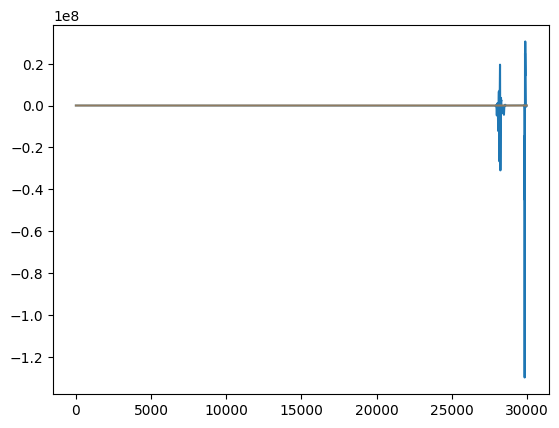

In [11]:
plt.plot(y_rec.detach().cpu()[2,0,:])
plt.plot(wavfull.detach().cpu()[2,:], alpha=.5)


In [12]:
n_down = model.text_aligner.n_down
mask = (length_to_mask(mel_input_length // (2 ** n_down))).to(device)
text_mask = length_to_mask(input_lengths).to(device)

text_aligner = model.text_aligner.to(device)
ppgs, s2s_pred, s2s_attn = text_aligner(mels, mask, texts)
s2s_attn = s2s_attn.transpose(-1, -2)
s2s_attn = s2s_attn[..., 1:]
s2s_attn = s2s_attn.transpose(-1, -2)
with torch.no_grad():
    attn_mask = (~mask).unsqueeze(-1).expand(mask.shape[0], mask.shape[1], text_mask.shape[-1]).float().transpose(-1, -2)
    attn_mask = attn_mask.float() * (~text_mask).unsqueeze(-1).expand(text_mask.shape[0], text_mask.shape[1], mask.shape[-1]).float()
    attn_mask = (attn_mask < 1)
s2s_attn.masked_fill_(attn_mask, 0.0)

with torch.no_grad():
    mask_ST = mask_from_lens(s2s_attn, input_lengths, mel_input_length // (2 ** n_down))
    s2s_attn_mono = maximum_path(s2s_attn, mask_ST)

text_encoder = model.text_encoder.to(device)
t_en = text_encoder(texts, input_lengths, text_mask)
asr = (t_en @ s2s_attn_mono)


def pipeline_split():
    res = []
    mel_len = mels.shape[-1]
    mel_len_min = mel_input_length.min().item()
    mel_len_st = mel_len_min // 2

    pitch_extractor = model.pitch_extractor.to(device)
    style_encoder = model.style_encoder.to(device)

    for idx in range(math.ceil(mel_len / split_len)):
        start = idx*split_len
        end = min((idx+1)*split_len, mel_len)

        en = asr[:, :, (start//2):(end//2)]
        gt = mels[:, :, start:end].detach()

        wav=[]
        wavidx = slice(start * 300, end * 300)
        full_len = wavidx.stop-wavidx.start
        for bib in range(len(mel_input_length)):
            y = waves[bib][wavidx]
            if full_len != y.shape[0]:
                y = np.pad(y, (0, full_len-y.shape[0]), 'constant')
            wav.append(torch.from_numpy(y).to(device))
        wavfull = torch.stack(wav).float().detach()
        
        # style reference (better to be different from the GT)
        start_st = 0 #np.random.randint(0, mel_len_min - mel_len_st)
        end_st = start_st + mel_len_st
        st = mels[:, :, start_st:end_st].detach()

        with torch.no_grad():    
            real_norm = log_norm(gt.unsqueeze(1)).squeeze(1).detach()
            F0_real, _, _ = pitch_extractor(gt.unsqueeze(1))

        s = style_encoder(st.unsqueeze(1)) # if multispeaker else gt.unsqueeze(1))

        # print(list(map(lambda x: x.shape, (en, F0_real, real_norm, s))))

        y_rec = model.decoder(en, F0_real, real_norm, s)
        res.append(y_rec.squeeze(1))
    return res

def pipeline_full():
    res = []
    mel_len = mels.shape[-1]
    split_len = mel_len
    mel_len_min = mel_input_length.min().item()
    mel_len_st = mel_len_min // 2

    pitch_extractor = model.pitch_extractor.to(device)
    style_encoder = model.style_encoder.to(device)

    for idx in range(math.floor(mel_len / split_len)):
        start = idx*split_len
        end = min((idx+1)*split_len, mel_len)

        en = asr[:, :, (start//2):(end//2)]
        gt = mels[:, :, start:end].detach()

        wav=[]
        wavidx = slice(start * 300, end * 300)
        full_len = wavidx.stop-wavidx.start
        for bib in range(len(mel_input_length)):
            y = waves[bib][wavidx]
            if full_len != y.shape[0]:
                y = np.pad(y, (0, full_len-y.shape[0]), 'constant')
            wav.append(torch.from_numpy(y).to(device))
        wavfull = torch.stack(wav).float().detach()
        
        # style reference (better to be different from the GT)
        start_st = 0 #np.random.randint(0, mel_len_min - mel_len_st)
        end_st = start_st + mel_len_st
        st = mels[:, :, start_st:end_st].detach()

        with torch.no_grad():    
            real_norm = log_norm(gt.unsqueeze(1)).squeeze(1).detach()
            F0_real, _, _ = pitch_extractor(gt.unsqueeze(1))

        s = style_encoder(st.unsqueeze(1)) # if multispeaker else gt.unsqueeze(1))

        # print(list(map(lambda x: x.shape, (en, F0_real, real_norm, s))))

        y_rec = model.decoder(en, F0_real, real_norm, s)
        res.append(y_rec.squeeze(1))
    return res, wavfull

with torch.no_grad():
    # res = pipeline_split()
    # res2 = pipeline_full()

    spl = pipeline_split()
    ful, wav = pipeline_full()

In [14]:
wav_valid_range = mel_input_length*300
#create a mask for the valid range of the wav
mask_wav_valid = torch.arange(0, wav.shape[1]).to(device).unsqueeze(0) < wav_valid_range.unsqueeze(1)


def get_loss(wav, y_rec):
    print(f"wav: {wav.shape}, y_rec: {y_rec.shape}")
    with torch.no_grad():
        d_loss = dl(wav.detach().unsqueeze(1).float(), y_rec.detach().unsqueeze(1)).mean()
        loss_mel = stft_loss(y_rec.squeeze(), wav.detach())
        loss_gen_all = gl(wav.detach().unsqueeze(1).float(), y_rec.unsqueeze(1)).mean()
        loss_slm = wl(wav.detach(), y_rec).mean()
    return d_loss.detach().cpu().numpy(), loss_mel.detach().cpu().numpy(), loss_gen_all.detach().cpu().numpy(), loss_slm.detach().cpu().numpy()

y_rec_ful=ful[0]
d, mel, gen, slm = get_loss(mask_wav_valid*wav, mask_wav_valid*y_rec_ful)
print(d, mel, gen, slm)

y_rec_split=torch.hstack(spl)
d, mel, gen, slm = get_loss(mask_wav_valid*wav, mask_wav_valid*y_rec_split)
print(d, mel, gen, slm)

# y_rec=torch.hstack(spl)
# d, mel, gen, slm = get_loss(wav[:,30000:2*30000], y_rec)
# print(d, mel, gen, slm)



wav: torch.Size([4, 189600]), y_rec: torch.Size([4, 189600])
12.740606 0.4165401 19.581734 2.0062373
wav: torch.Size([4, 189600]), y_rec: torch.Size([4, 189600])
5.6251125 0.43010363 7.849325 2.1533225


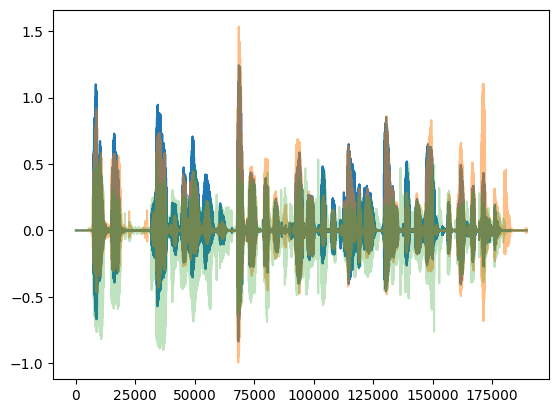

In [15]:
plt.plot(y_rec_ful.detach().cpu()[0,:])
plt.plot(y_rec_split.detach().cpu()[0,:],alpha=.5)
plt.plot(wav[0,:].detach().cpu(), alpha=.3)

In [19]:
from IPython.display import Audio

sample_rate = 24000  # From the config sr variable defined earlier
Audio(y_rec_split[0,:].cpu().numpy(), rate=sample_rate)

In [34]:
mask_wav_valid.shape

torch.Size([4, 189600])

In [21]:
spl[0].shape, ful[0].shape

(torch.Size([4, 1, 30000]), torch.Size([4, 1, 189600]))

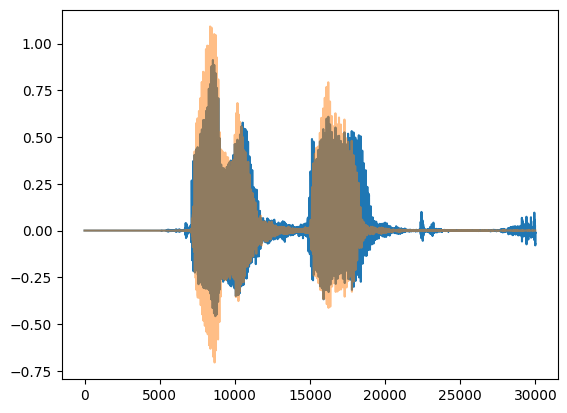

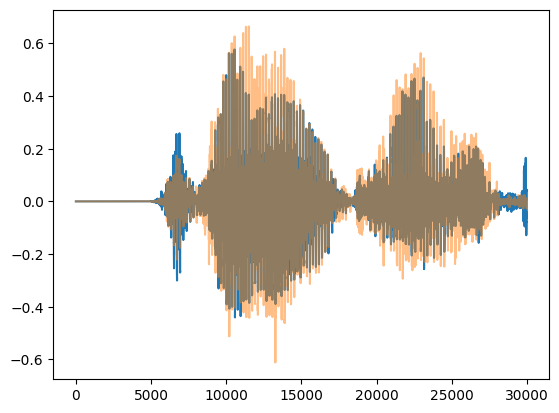

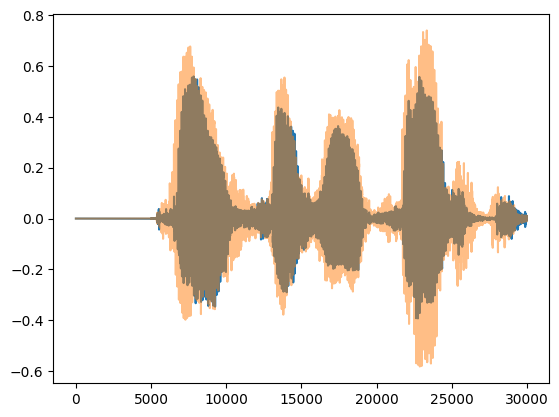

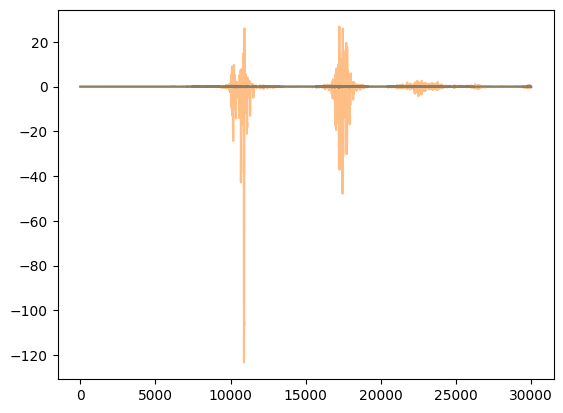

In [27]:
for j in range(4):
    plt.figure()
    plt.plot(spl[0].detach().cpu()[j,0,:])
    plt.plot(ful[0].detach().cpu()[j,0,:30000], alpha=.5)

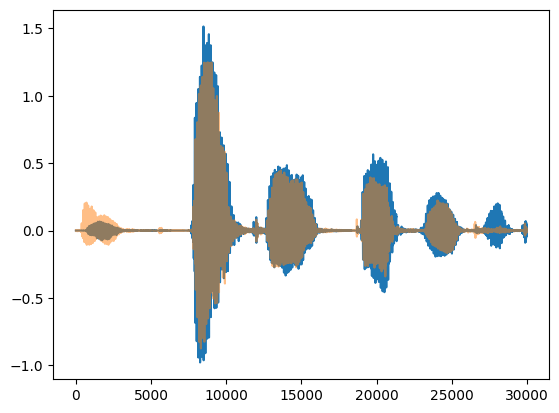

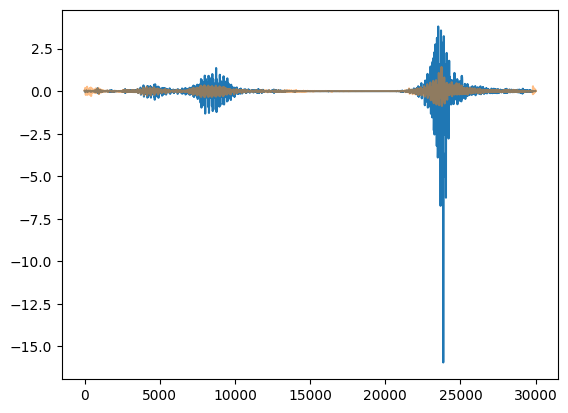

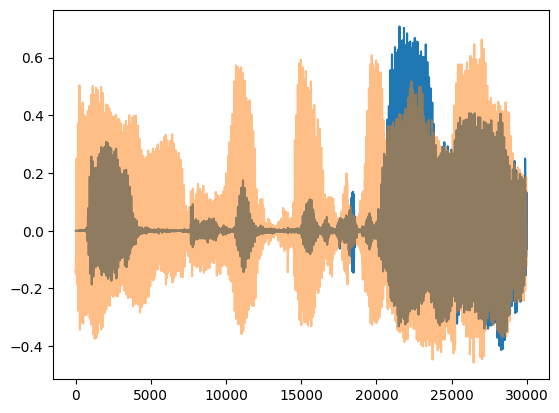

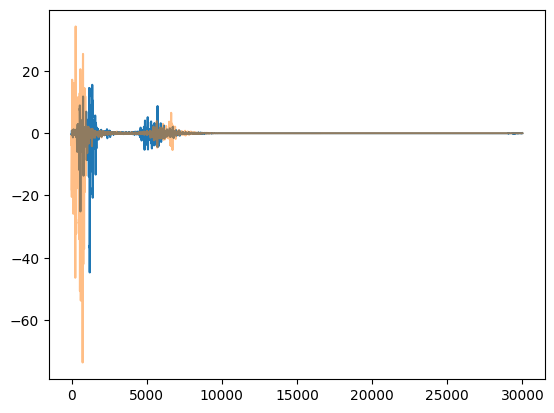

In [29]:
for j in range(4):
    plt.figure()
    plt.plot(spl[2].detach().cpu()[j,0,:])
    plt.plot(ful[0].detach().cpu()[j,0,2*30000:3*30000], alpha=.5)

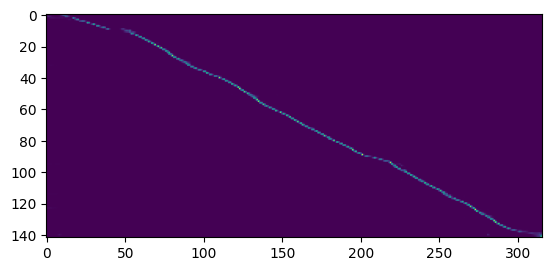

In [12]:
plt.imshow(s2s_attn.detach().cpu().numpy()[0,:,:])

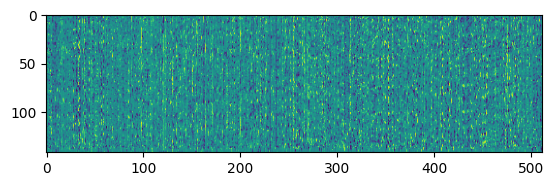

In [17]:
plt.imshow(t_en.detach().cpu().numpy()[0,:,:].T)

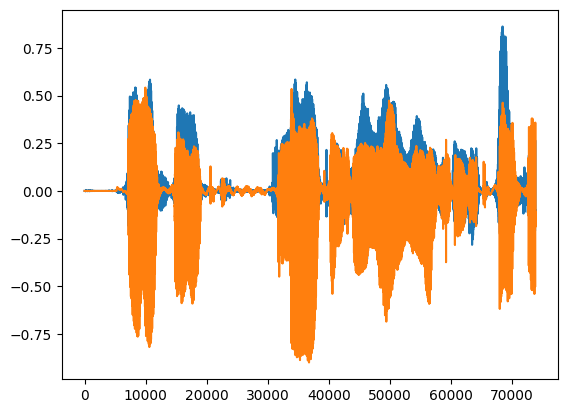

In [18]:
plt.plot(y_rec.detach().cpu().numpy()[0,0,:])
plt.plot(wav.detach().cpu().numpy()[0,:])


In [19]:
# optimizer.zero_grad()   
# d_loss = dl(wav.detach().unsqueeze(1).float(), y_rec.detach()).mean()
# d_loss.backward()

In [20]:
print(model.decoder)

Decoder(
  (decode): ModuleList(
    (0-2): 3 x AdainResBlk1d(
      (actv): LeakyReLU(negative_slope=0.2)
      (upsample): UpSample1d()
      (conv1): Conv1d(1090, 1024, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv2): Conv1d(1024, 1024, kernel_size=(3,), stride=(1,), padding=(1,))
      (norm1): AdaIN1d(
        (norm): InstanceNorm1d(1090, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
        (fc): Linear(in_features=128, out_features=2180, bias=True)
      )
      (norm2): AdaIN1d(
        (norm): InstanceNorm1d(1024, eps=1e-05, momentum=0.1, affine=False, track_running_stats=False)
        (fc): Linear(in_features=128, out_features=2048, bias=True)
      )
      (conv1x1): Conv1d(1090, 1024, kernel_size=(1,), stride=(1,), bias=False)
      (dropout): Dropout(p=0.0, inplace=False)
      (pool): Identity()
    )
    (3): AdainResBlk1d(
      (actv): LeakyReLU(negative_slope=0.2)
      (upsample): UpSample1d()
      (conv1): Conv1d(1090, 512, kernel_si

In [21]:
print(model.decoder.decode[0].conv1.weight)

tensor([[[-3.1577e-03, -4.5604e-03, -1.3130e-03],
         [-7.4713e-03, -4.0875e-03, -1.6874e-03],
         [-1.8655e-02, -1.6160e-02, -1.5443e-02],
         ...,
         [ 1.6459e-04, -9.2050e-03,  1.0020e-03],
         [ 4.8934e-04,  3.6348e-03, -3.0966e-03],
         [ 2.2261e-02, -2.4288e-03, -6.0464e-03]],

        [[ 3.4839e-03, -4.1256e-03, -7.0544e-03],
         [ 6.9256e-03,  5.5016e-03, -5.4912e-04],
         [ 3.7970e-03,  2.5421e-03, -6.2889e-04],
         ...,
         [-1.6219e-02, -6.5407e-03, -3.1753e-03],
         [ 7.8979e-03, -3.8319e-03,  3.3032e-03],
         [-9.4772e-03, -5.9077e-03, -5.8213e-03]],

        [[ 1.1333e-03,  8.1549e-03, -8.0091e-03],
         [-4.3948e-03,  2.9814e-02, -8.0655e-03],
         [ 2.2905e-04,  1.3467e-03, -4.8193e-03],
         ...,
         [-1.1733e-03,  6.3818e-03,  1.3292e-02],
         [ 2.9505e-02, -4.6445e-02,  1.0280e-02],
         [-2.0610e-03, -1.1820e-03,  3.2774e-03]],

        ...,

        [[ 1.2623e-03, -1.8139e-02, -1

In [22]:

torch.cuda.memory._record_memory_history(
       max_entries=1000000, enabled='all', stacks="python"
   )
optimizer.zero_grad()   
d_loss_full = dl(wav.detach().unsqueeze(1).float(), y_rec.detach())
# d_loss = d_loss_full.mean()
# d_loss.backward()
torch.cuda.memory._dump_snapshot(f"memory.pickle")
torch.cuda.memory._record_memory_history(enabled=None)

In [ ]:
os.system(f"python {memory_viz_loc} trace_plot memory.pickle -o memory.html")


In [ ]:
d=dl(wav.detach().unsqueeze(1).float(), y_rec.detach())


torch.Size([])

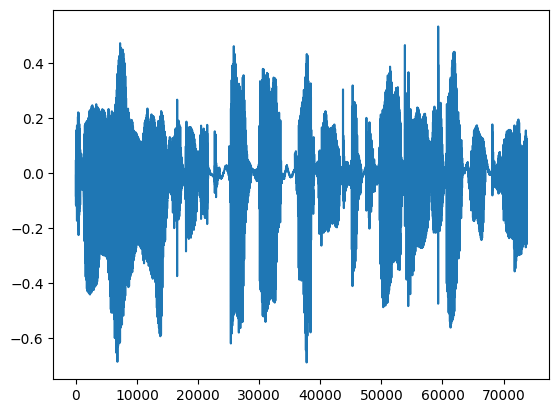

In [21]:
plt.plot(wav.detach().cpu().numpy()[0,:])
# plt.plot(y_rec.detach().cpu().numpy()[0,0,:])
# for name, param in model.text_aligner.to(device).named_parameters():
#     print(name, param.device)

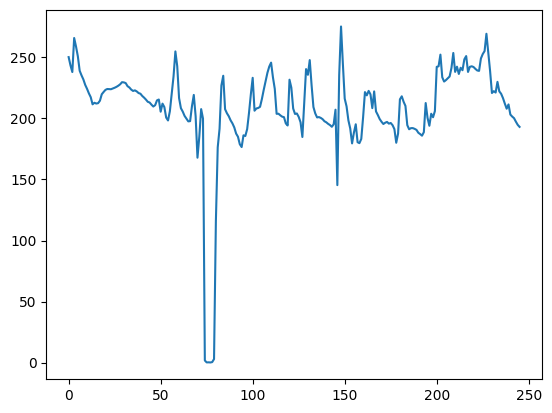

In [24]:
plt.plot(F0_real.cpu()[0,:])

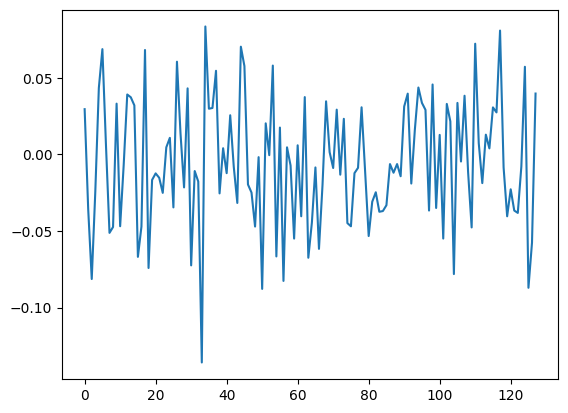